<a href="https://colab.research.google.com/github/Emma-Asoliya/cervical-screening-app/blob/main/Cervical_Screening_Model_v5_after_acid_only.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Cervical Screening Model: after-acid photos only

======

Colposcopy images from 332 patients. Each patient has photos taken before and after acetic acid is applied to the cervix. The binary label is normal vs abnormal.

**This copy trains and evaluates on the after-acid (post) photos only.** Earlier runs showed the after-acid photos carried the signal, and acetic acid is what turns abnormal tissue white, so the before-acid photos are left out of every experiment below.

What changed compared with v4:

- One line in section 5 (`everyone = is_post`) restricts every experiment to after-acid photos. All the helper functions already used `everyone` as their default, so training, scoring and patient-level AUC all follow it.
- The fold assignment is untouched, so every patient stays in the same fold as in earlier runs and the numbers are directly comparable.
- Results go to a new Drive folder (`cervical_v2_postonly`) so nothing from the earlier runs is overwritten. The processed array and metadata are still read from `cervical_v2`.
- The pre-acid vs post-acid ablation is gone; experiment B now compares colour vs grayscale on after-acid photos.
- Section 12 (app export) is trained on after-acid photos, so the app must only be given after-acid photos.

Two things make this harder than standard image classification. Class imbalance: roughly 2:1 normal to abnormal. And multiple photos per patient. If photos from the same patient end up in both train and test, the AUC numbers mean less than they look. Every split here is patient-level.

Experiments in order (all after-acid photos only):

| Name | What it does |
|------|-------------|
| A | Small CNN from scratch |
| B | Same CNN, colour vs grayscale |
| T1 | Frozen ImageNet backbones, logistic regression head |
| T2 / T3 | Fine-tuning with different unfreeze depths |
| T4 | Fine-tuning with AdamW, label smoothing, stronger dropout |


## 1. Setup

======

Mount Drive, create the output folder, and import everything the notebook depends on. All imports live here so each experiment section can focus on the model.


In [41]:
from google.colab import drive
drive.mount("/content/drive")

import os
DATASET_ROOT = "/content/drive/MyDrive/Colposcopy_Data_In_Brief"
DATA_DIR = "/content/drive/MyDrive/cervical_v2"           # processed array + meta.csv (shared with earlier runs)
OUT      = "/content/drive/MyDrive/cervical_v2_postonly"  # predictions and models for this after-acid-only run
os.makedirs(DATA_DIR, exist_ok=True)
os.makedirs(OUT, exist_ok=True)

print("dataset folder found:", os.path.isdir(DATASET_ROOT))
print("inside it:", sorted(os.listdir(DATASET_ROOT)))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
dataset folder found: True
inside it: ['.DS_Store', '01_Normal', '02_Abnormal']


In [42]:
# All imports in one place
import os, time, hashlib, io, gc

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf
from sklearn.model_selection    import StratifiedGroupKFold
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics            import (
    roc_auc_score, roc_curve, auc,
    confusion_matrix, classification_report,
)
from sklearn.linear_model  import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline      import make_pipeline
from concurrent.futures    import ThreadPoolExecutor
from PIL import Image

SEED = 42
tf.keras.utils.set_random_seed(SEED)

W, H = 256, 192          # resize target (width x height)
PATCH_W, PATCH_H = 345, 100  # annotation patch in top-left corner to zero out

print("GPU:", tf.config.list_physical_devices("GPU"))

GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 2. Data loading and EDA

======

Build the patient/photo table, parse pre vs post labels from filenames, and look at a sample of images. None of these cells need the pixel array yet.


In [43]:
import pandas as pd

rows = []
for folder, label in [("01_Normal", 0), ("02_Abnormal", 1)]:
  folder_path = os.path.join(DATASET_ROOT, folder)
  for patient in sorted(os.listdir(folder_path)):
    patient_path = os.path.join(folder_path, patient)
    if not os.path.isdir(patient_path):
      continue
    for fname in sorted(os.listdir(patient_path)):
      if fname.lower().endswith(".jpg"):
        rows.append({"patient_id": patient, "filename": fname,
                     "image_path": os.path.join(patient_path, fname),
                     "label": label})
meta = pd.DataFrame(rows)
print(meta.shape)
print("photos per class (0 = Normal, 1 = Abnormal):", meta["label"].value_counts().to_dict())
print("patients per class:", meta.groupby("label")["patient_id"].nunique().to_dict())
print("patients appearing in both classes:", int((meta.groupby("patient_id")["label"].nunique() > 1). sum()))

(3359, 4)
photos per class (0 = Normal, 1 = Abnormal): {0: 2134, 1: 1225}
patients per class: {0: 210, 1: 122}
patients appearing in both classes: 0


In [44]:
meta["image_type"] = (meta["filename"].str.lower().str.extract(r"^([a-z]+)")[0]
                      .map({"p": "pre", "po": "post"}).fillna("other"))
print(meta["image_type"].value_counts().to_dict())
print(meta[meta["image_type"] == "other"][["patient_id", "filename"]])

{'post': 1692, 'pre': 1664, 'other': 3}
     patient_id      filename
2479   buth_081        pb.jpg
2994   buth_253       -2a.jpg
3182   buth_304  buth_304.jpg


## 3. Preprocessing

======

Load every image, zero out the annotation patch in the top-left corner, resize to 256x192, and compute an MD5 fingerprint per photo. Then drop exact duplicates and photos with ambiguous pre/post labels.

The MD5 step matters: some patients have identical photos stored under different filenames. Keeping both could give the model a small shortcut on those patients.

If the processed array already exists on Drive (`X_256x192.npy`), this section can be skipped and the array loaded in section 5.


In [45]:
import hashlib, io, time
import numpy as np
from PIL import Image
from concurrent.futures import ThreadPoolExecutor

W, H = 256, 192
PATCH_W, PATCH_H = 345, 100

def read_one(path):
  with open(path, "rb") as f:
    raw = f.read()
  fingerprint = hashlib.md5(raw).hexdigest()
  im = Image.open(io.BytesIO(raw)).convert("RGB")
  if im.size != (640, 480):
    raise ValueError(f"unexpected size {im.size} for {path}")
  a = np.array(im)
  a[:PATCH_H, :PATCH_W] = 0
  small = np.array(Image.fromarray(a).resize((W, H), Image.LANCZOS))
  return fingerprint, small

t0 = time.time()
with ThreadPoolExecutor(max_workers=8) as pool:
  results = list(pool.map(read_one, meta["image_path"]))
  meta["md5"] = [r[0] for r in results]
  X_all = np.stack([r[1] for r in results])
  del results
  assert X_all.shape == (len(meta), H, W, 3), "photo array has the wrong shape"
  print("done:", X_all.shape, X_all.dtype, f"in{(time.time() - t0) / 60:.1f} min")

done: (3359, 192, 256, 3) uint8 in0.6 min


In [46]:
shared = meta.groupby("md5")["patient_id"].nunique()
print("identical photos shared between DIFFERENT patients:", int((shared > 1).sum()))

clash = meta.groupby("md5")["image_type"].nunique()
clash_ids = set(clash[clash > 1].index)
print("identical photos named both pre and post:", len(clash_ids))
meta.loc[meta["md5"].isin(clash_ids), "image_type"] = "ambiguous"

meta["name_len"] = meta["filename"].str.len()
order = meta.sort_values(["patient_id", "md5", "name_len", "filename"]).index
keep_labels = meta.loc[order].drop_duplicates(["patient_id", "md5"], keep="first").index
keep_mask = meta.index.isin(keep_labels) & meta["image_type"].isin(["pre", "post"]).values

print("before:", len(meta), "| after removing copies, ambiguous and other:", int(keep_mask.sum()))
X = X_all[keep_mask]
meta = meta[keep_mask].drop(columns=["name_len"]).reset_index(drop=True)
del X_all
assert len(meta) == len(X)
print("final:", len(meta), "photos |", meta["patient_id"].nunique(), "patients")
print(meta["image_type"].value_counts().to_dict())

identical photos shared between DIFFERENT patients: 0
identical photos named both pre and post: 10
before: 3359 | after removing copies, ambiguous and other: 3310
final: 3310 photos | 332 patients
{'post': 1671, 'pre': 1639}


In [47]:
repeat_in_patient = int(meta.duplicated(["patient_id", "md5"]).sum())
named_twice = int((meta.groupby("md5")["image_type"].nunique()> 1).sum())
print("repeated photos inside a patient:", repeat_in_patient)
print("identical photos still carrying two different names:", named_twice)
print("buth_228 photos left:", sorted(meta.loc[meta["patient_id"] == "buth_228", "filename"]))

repeated photos inside a patient: 0
identical photos still carrying two different names: 0
buth_228 photos left: ['p1.jpg', 'po1.jpg']


## 4. Cross-validation setup

======

StratifiedGroupKFold with 5 folds. Stratified keeps the normal/abnormal ratio balanced across folds. Group prevents any patient from appearing in more than one fold.

Within each outer fold, an inner 6-way split provides the validation set used for early stopping. The held-out test fold is never touched during training.

The folds are built on all photos, exactly as in earlier runs. Training later uses only the after-acid photos, but each patient keeps the same fold, so results stay comparable with the earlier experiments.


In [48]:
from sklearn.model_selection import StratifiedGroupKFold

N_FOLDS, SEED = 5, 42
meta["fold"] = -1
splitter = StratifiedGroupKFold(N_FOLDS, shuffle=True, random_state=SEED)
for k, (_, test_idx) in enumerate(splitter.split(meta, meta["label"], meta["patient_id"])):
  meta.loc[test_idx, "fold"] = k

assert (meta["fold"] >= 0).all(), "some photos were not given a fold"
assert meta.groupby("patient_id")["fold"].nunique().max() == 1, "a patient is split across folds"

pat = meta.groupby("patient_id").agg(fold=("fold", "first"), label=("label", "first"))
per_fold = pd.DataFrame({
    "patients": pat.groupby("fold").size(),
    "abnormal_patients": pat.groupby("fold")["label"].sum(),
    "pre_photos": meta[meta["image_type"] == "pre"].groupby("fold").size(),
    "post_photos": meta[meta["image_type"] == "post"].groupby("fold").size()})
print(per_fold)

counts = meta.pivot_table(index="patient_id", columns="image_type",
                          values="label", aggfunc="size", fill_value=0)
print("patients with no pre-acid photos:", int((counts["pre"] == 0).sum()),
      "| with no post-acid photos:", int((counts["post"] == 0).sum()))

      patients  abnormal_patients  pre_photos  post_photos
fold                                                      
0           66                 24         326          340
1           67                 25         330          338
2           66                 25         319          318
3           66                 18         337          351
4           67                 30         327          324
patients with no pre-acid photos: 0 | with no post-acid photos: 0


### Save processed data and sample images

Saves the array and the metadata (with folds) to Drive, then shows four before-acid and four after-acid photos from different patients and folds.


saved to /content/drive/MyDrive/cervical_v2 | 488 MB


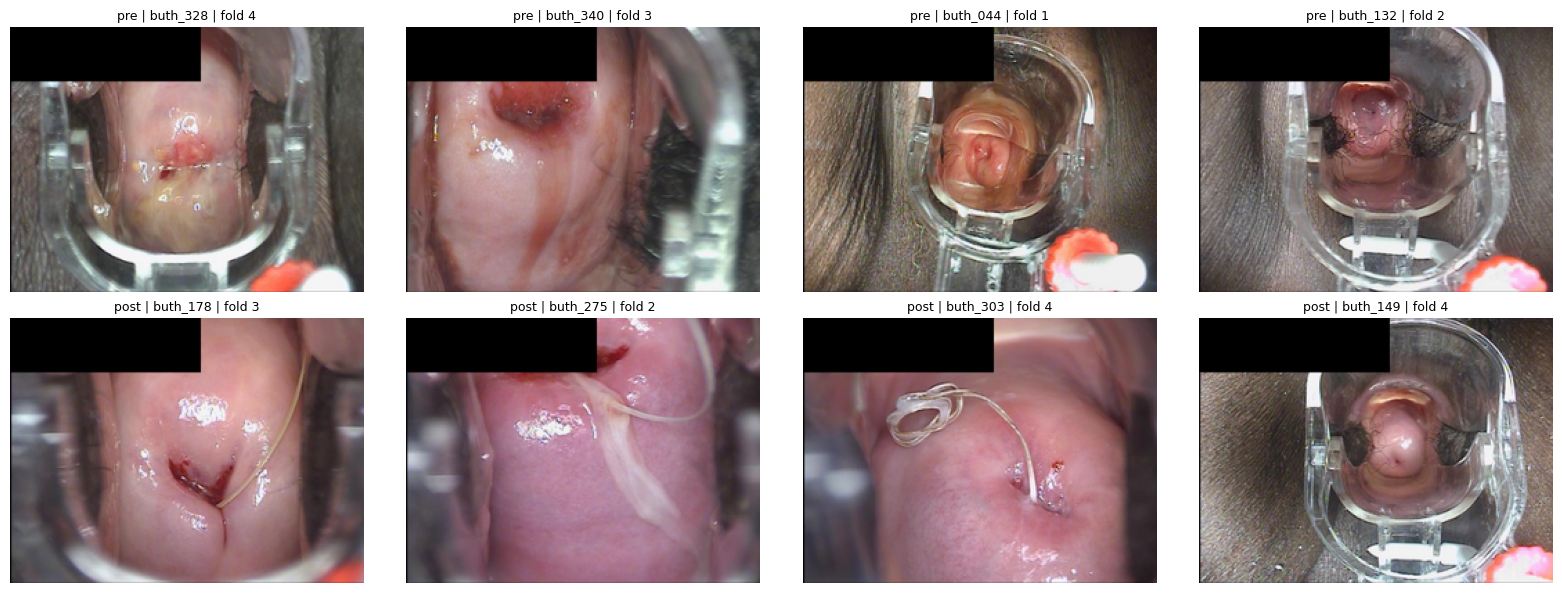

In [49]:
# Save the processed array and metadata (now including the fold column), then plot samples.
# This cell must come AFTER the fold setup above: it needs meta["fold"].
assert "fold" in meta.columns and (meta["fold"] >= 0).all(), "run the fold setup cell first"

x_path = f"{DATA_DIR}/X_{W}x{H}.npy"
if not os.path.exists(x_path):          # the array is large, only write it once
    np.save(x_path, X)
meta.to_csv(f"{DATA_DIR}/meta.csv", index=False)   # always refresh: carries the fold column
print("saved to", DATA_DIR, "|", round(os.path.getsize(x_path) / 1e6), "MB")

fig, axes = plt.subplots(2, 4, figsize=(16, 6))
for r, kind in enumerate(["pre", "post"]):
  picks = meta[meta["image_type"] == kind].sample(4, random_state=1).index
  for ax, i in zip(axes[r], picks):
    ax.imshow(X[i])
    ax.set_title(f"{kind} | {meta.loc[i, 'patient_id']} | fold {meta.loc[i, 'fold']}", fontsize=9)
    ax.axis("off")

plt.tight_layout()
plt.show()


## 5. Utilities and model definitions

======

All model builders, training loops, and evaluation helpers. Run this entire section before any experiment. The data load at the top is a guard: if `X` and `meta` are already in memory from sections 3-4, it skips the file read. That cell also restricts every experiment to after-acid photos (`everyone = is_post`).


In [50]:
# Load processed array from Drive if not already in memory
DATA_DIR = "/content/drive/MyDrive/cervical_v2"           # processed array + meta.csv
OUT      = "/content/drive/MyDrive/cervical_v2_postonly"  # outputs of this run
os.makedirs(OUT, exist_ok=True)

if "X" not in globals() or "meta" not in globals():
    X    = np.load(f"{DATA_DIR}/X_256x192.npy")
    meta = pd.read_csv(f"{DATA_DIR}/meta.csv")

assert X.shape == (len(meta), 192, 256, 3) and len(meta) == 3310, "shape mismatch"
print("all photos:", X.shape, "| patients:", meta["patient_id"].nunique())

# Image-type masks
is_pre  = (meta["image_type"] == "pre").values
is_post = (meta["image_type"] == "post").values

# ======
# KEY CHANGE: every experiment in this notebook uses AFTER-ACID photos only.
# run_cv, run_cv_ft, patient_table, score, add_result and evaluate_experiment all
# default to `everyone`, so pointing it at is_post restricts the whole notebook.
# ======
everyone = is_post.copy()

# Fold column used for cross-validation splits (unchanged from earlier runs)
y    = meta["label"].values
fold = meta["fold"].values

# What the after-acid subset looks like
post = meta[is_post]
pp = post.groupby("patient_id").agg(label=("label", "first"), fold=("fold", "first"))
print(f"after-acid photos used: {int(is_post.sum())} (before-acid photos ignored: {int(is_pre.sum())})")
print(f"patients with after-acid photos: {len(pp)} | abnormal: {int(pp['label'].sum())} | normal: {int((pp['label'] == 0).sum())}")
print("patients per fold (abnormal in brackets):")
print(pp.groupby("fold")["label"].agg(patients="size", abnormal="sum").T.to_string())


all photos: (3310, 192, 256, 3) | patients: 332
after-acid photos used: 1671 (before-acid photos ignored: 1639)
patients with after-acid photos: 332 | abnormal: 122 | normal: 210
patients per fold (abnormal in brackets):
fold       0   1   2   3   4
patients  66  67  66  66  67
abnormal  24  25  25  18  30


In [51]:
# ======
# Augmentation blocks
# Applied as part of the model graph (training-only via Keras behavior)
# ======

def augment_block(x):
    x = tf.keras.layers.RandomFlip("horizontal")(x)
    x = tf.keras.layers.RandomRotation(0.05, fill_mode="constant", fill_value=0.0)(x)
    x = tf.keras.layers.RandomZoom(0.10, fill_mode="constant", fill_value=0.0)(x)
    x = tf.keras.layers.RandomTranslation(0.05, 0.05, fill_mode="constant", fill_value=0.0)(x)
    x = tf.keras.layers.RandomBrightness(0.10, value_range=(0.0, 1.0))(x)
    x = tf.keras.layers.RandomContrast(0.10, value_range=(0.0, 1.0))(x)
    return x

def augment_block_strong(x):
    """Stronger augmentation used in T4 to counteract overfitting."""
    x = tf.keras.layers.RandomFlip("horizontal_and_vertical")(x)
    x = tf.keras.layers.RandomRotation(0.10, fill_mode="constant", fill_value=0.0)(x)
    x = tf.keras.layers.RandomZoom(0.15, fill_mode="constant", fill_value=0.0)(x)
    x = tf.keras.layers.RandomTranslation(0.10, 0.10, fill_mode="constant", fill_value=0.0)(x)
    x = tf.keras.layers.RandomBrightness(0.15, value_range=(0.0, 1.0))(x)
    x = tf.keras.layers.RandomContrast(0.15, value_range=(0.0, 1.0))(x)
    return x

# ======
# Small CNN (baseline, ~24k params)
# Three conv blocks, global average pooling, one dropout layer
# ======

def build_small_cnn():
    inp = tf.keras.Input(shape=(192, 256, 3))
    x   = tf.keras.layers.Rescaling(1 / 255.0)(inp)
    x   = augment_block(x)
    for filters in (16, 32, 64):
        x = tf.keras.layers.Conv2D(filters, 3, activation="relu")(x)
        x = tf.keras.layers.MaxPooling2D()(x)
    x   = tf.keras.layers.GlobalAveragePooling2D()(x)
    x   = tf.keras.layers.Dropout(0.3)(x)
    out = tf.keras.layers.Dense(1, activation="sigmoid")(x)
    return tf.keras.Model(inp, out)

# ======
# Deeper CNN with batch normalization (~1.2M params)
# Used in experiment A2; kept here for reference
# ======

def conv_bn(x, filters, kernel=3, strides=1):
    x = tf.keras.layers.Conv2D(filters, kernel, strides=strides,
                                padding="same", use_bias=False)(x)
    x = tf.keras.layers.BatchNormalization()(x)
    return tf.keras.layers.ReLU()(x)

def build_deeper_cnn():
    inp = tf.keras.Input(shape=(192, 256, 3))
    x   = tf.keras.layers.Rescaling(1 / 255.0)(inp)
    x   = augment_block(x)
    x   = conv_bn(x, 32, kernel=5, strides=2)
    for filters in (32, 64, 128, 256):
        x = conv_bn(x, filters)
        x = conv_bn(x, filters)
        x = tf.keras.layers.MaxPooling2D()(x)
    x   = tf.keras.layers.GlobalAveragePooling2D()(x)
    x   = tf.keras.layers.Dropout(0.4)(x)
    out = tf.keras.layers.Dense(1, activation="sigmoid")(x)
    return tf.keras.Model(inp, out)

# ======
# Transfer learning backbone builder
# Backbone weights stay frozen until run_cv_ft unfreezes them
# ======

apps = tf.keras.applications
backbones = {
    "densenet121":    (apps.DenseNet121,    apps.densenet.preprocess_input),
    "resnet50":       (apps.ResNet50,       apps.resnet50.preprocess_input),
    "efficientnetb0": (apps.EfficientNetB0, apps.efficientnet.preprocess_input),
    "mobilenetv2":    (apps.MobileNetV2,    apps.mobilenet_v2.preprocess_input),
}

def build_transfer(backbone, dropout=0.3, aug_fn=None):
    """Frozen backbone with augmentation and a single dense head."""
    aug_fn = aug_fn or augment_block
    builder, prep = backbones[backbone]
    net = builder(include_top=False, weights="imagenet", input_shape=(192, 256, 3))
    net.trainable = False

    inp = tf.keras.Input(shape=(192, 256, 3))
    x   = tf.keras.layers.Rescaling(1 / 255.0)(inp)
    x   = aug_fn(x)
    x   = tf.keras.layers.Rescaling(255.0)(x)   # undo before preprocess_input
    x   = prep(x)
    x   = net(x, training=False)
    x   = tf.keras.layers.GlobalAveragePooling2D()(x)
    x   = tf.keras.layers.Dropout(dropout)(x)
    out = tf.keras.layers.Dense(1, activation="sigmoid")(x)
    model = tf.keras.Model(inp, out)
    assert any(layer is net for layer in model.layers), "backbone not connected"
    return net, model

In [52]:
# ======
# 5-fold cross-validation loop for from-scratch models
# Returns: (oof_predictions, list_of_fold_histories)
# Histories are None for folds loaded from disk (already done)
# save_models=True also stores each fold's model at OUT/models/<name>/fold<k>.keras
# seed changes the inner split and weight init only (outer folds stay fixed)
# ======

def run_cv(build_fn, name, keep=None, max_epochs=40, patience=6,
           lr=1e-3, batch=32, min_epochs=0, loss="binary_crossentropy",
           weight_decay=None, save_models=False, seed=SEED):

    keep = everyone if keep is None else keep
    patient = meta["patient_id"].values
    path = f"{OUT}/oof_{name}.npy"
    pred = np.load(path) if os.path.exists(path) else np.full(len(meta), np.nan)
    histories = []
    model_dir = f"{OUT}/models/{name}"
    if save_models:
        os.makedirs(model_dir, exist_ok=True)

    for f in range(5):
        test_idx = np.where(keep & (fold == f))[0]
        model_path = f"{model_dir}/fold{f}.keras"
        done = (not np.isnan(pred[test_idx]).any()
                and (not save_models or os.path.exists(model_path)))
        if done:
            print(f"fold {f}: already done, skipping")
            histories.append(None)
            continue

        t0   = time.time()
        pool = np.where(keep & (fold != f))[0]
        inner = StratifiedGroupKFold(6, shuffle=True, random_state=seed + f)
        tr_pos, va_pos = next(inner.split(pool, y[pool], patient[pool]))
        tr, va = pool[tr_pos], pool[va_pos]

        w  = compute_class_weight("balanced", classes=np.array([0, 1]), y=y[tr])
        cw = {0: w[0], 1: w[1]}

        tf.keras.backend.clear_session()
        tf.keras.utils.set_random_seed(seed + f)
        model = build_fn()

        opt = (tf.keras.optimizers.AdamW(lr, weight_decay=weight_decay)
               if weight_decay else tf.keras.optimizers.Adam(lr))
        model.compile(optimizer=opt, loss=loss,
                      metrics=[tf.keras.metrics.AUC(name="auc")])

        stopper = tf.keras.callbacks.EarlyStopping(
            monitor="val_auc", mode="max",
            patience=patience, restore_best_weights=True,
            start_from_epoch=min_epochs)

        hist = model.fit(
            X[tr], y[tr], validation_data=(X[va], y[va]),
            epochs=max_epochs, batch_size=batch,
            class_weight=cw, callbacks=[stopper], verbose=0)

        pred[test_idx] = model.predict(X[test_idx], batch_size=64, verbose=0).ravel()
        np.save(path, pred)
        histories.append(hist.history)

        if save_models:
            model.save(model_path)
            # sanity check: the reloaded model must reproduce the saved predictions
            chk = tf.keras.models.load_model(model_path)
            probe = test_idx[:8]
            assert np.allclose(chk.predict(X[probe], verbose=0).ravel(), pred[probe], atol=1e-4), \
                f"fold {f}: reloaded model does not match saved predictions"

        best = int(np.argmax(hist.history["val_auc"])) + 1
        print(f"fold {f}: {len(hist.history['loss'])} epochs "
              f"(best {best}), val AUC {max(hist.history['val_auc']):.3f}, "
              f"{(time.time() - t0) / 60:.1f} min")

    return pred, histories


# ======
# Fine-tuning loop: warm up head, then unfreeze last N backbone layers
# Returns: (oof_predictions, list_of_fold_histories)
# ======

def run_cv_ft(backbone, name, unfreeze_last, keep=None,
              head_epochs=5, max_ft_epochs=30, patience=8,
              lr_head=1e-3, lr_ft=5e-5, batch=32,
              dropout=0.3, aug_fn=None,
              weight_decay=None, loss="binary_crossentropy"):

    assert unfreeze_last >= 1
    keep = everyone if keep is None else keep
    patient = meta["patient_id"].values
    path = f"{OUT}/oof_{name}.npy"
    pred = np.load(path) if os.path.exists(path) else np.full(len(meta), np.nan)
    histories = []

    for f in range(5):
        test_idx = np.where(keep & (fold == f))[0]
        if not np.isnan(pred[test_idx]).any():
            print(f"fold {f}: already done, skipping")
            histories.append(None)
            continue

        t0   = time.time()
        pool = np.where(keep & (fold != f))[0]
        inner = StratifiedGroupKFold(6, shuffle=True, random_state=SEED + f)
        tr_pos, va_pos = next(inner.split(pool, y[pool], patient[pool]))
        tr, va = pool[tr_pos], pool[va_pos]

        w  = compute_class_weight("balanced", classes=np.array([0, 1]), y=y[tr])
        cw = {0: w[0], 1: w[1]}
        n0, n1 = int((y[tr] == 0).sum()), int((y[tr] == 1).sum())
        print(f"fold {f}: {len(tr)} photos | Normal {n0} x {w[0]:.2f} | Abnormal {n1} x {w[1]:.2f}")

        tf.keras.backend.clear_session()
        tf.keras.utils.set_random_seed(SEED + f)
        net, model = build_transfer(backbone, dropout=dropout, aug_fn=aug_fn)

        # Step 1: warm up the dense head with the backbone fully frozen
        model.compile(optimizer=tf.keras.optimizers.Adam(lr_head),
                      loss=loss, metrics=[tf.keras.metrics.AUC(name="auc")])
        model.fit(X[tr], y[tr], validation_data=(X[va], y[va]),
                  epochs=head_epochs, batch_size=batch, class_weight=cw, verbose=0)

        # Step 2: unfreeze the last N backbone layers (keep BatchNorm frozen)
        net.trainable = True
        for layer in net.layers[:-unfreeze_last]:
            layer.trainable = False
        for layer in net.layers[-unfreeze_last:]:
            if isinstance(layer, tf.keras.layers.BatchNormalization):
                layer.trainable = False

        n_train = sum(int(np.prod(v.shape)) for v in model.trainable_weights)
        print(f"fold {f}: {n_train:,} trainable params after unfreeze")
        assert n_train > 100_000, "backbone may not be connected"

        opt = (tf.keras.optimizers.AdamW(lr_ft, weight_decay=weight_decay)
               if weight_decay else tf.keras.optimizers.Adam(lr_ft))
        model.compile(optimizer=opt, loss=loss,
                      metrics=[tf.keras.metrics.AUC(name="auc")])

        stopper = tf.keras.callbacks.EarlyStopping(
            monitor="val_auc", mode="max",
            patience=patience, restore_best_weights=True, start_from_epoch=3)

        hist = model.fit(
            X[tr], y[tr], validation_data=(X[va], y[va]),
            epochs=max_ft_epochs, batch_size=batch,
            class_weight=cw, callbacks=[stopper], verbose=0)

        pred[test_idx] = model.predict(X[test_idx], batch_size=64, verbose=0).ravel()
        np.save(path, pred)
        histories.append(hist.history)

        best = int(np.argmax(hist.history["val_auc"])) + 1
        print(f"fold {f}: {len(hist.history['loss'])} epochs (best {best}), "
              f"train AUC {hist.history['auc'][-1]:.2f}, "
              f"val AUC {max(hist.history['val_auc']):.3f}, "
              f"{(time.time() - t0) / 60:.1f} min")

    return pred, histories

In [53]:
# ======
# Patient-level scoring
# Photos from the same patient are averaged before computing AUC
# ======

def patient_table(pred, keep=None):
    keep = everyone if keep is None else keep
    m = keep & ~np.isnan(pred)
    d = pd.DataFrame({
        "patient": meta["patient_id"].values[m],
        "fold":    meta["fold"].values[m],
        "y":       meta["label"].values[m],
        "p":       pred[m],
    })
    return d.groupby("patient").agg(y=("y","first"), p=("p","mean"), fold=("fold","first"))


def score(pred, label, keep=None):
    """Print patient AUC with bootstrap CI and per-fold breakdown."""
    per = patient_table(pred, keep)
    auc_val = roc_auc_score(per["y"], per["p"])

    rng = np.random.default_rng(0)
    boots = []
    for _ in range(1000):
        i = rng.integers(0, len(per), len(per))
        if per["y"].values[i].min() != per["y"].values[i].max():
            boots.append(roc_auc_score(per["y"].values[i], per["p"].values[i]))
    lo, hi  = np.percentile(boots, [2.5, 97.5])
    by_fold = [roc_auc_score(g["y"], g["p"]) for _, g in per.groupby("fold")]

    print(f"{label}: patient AUC {auc_val:.3f} (95% CI {lo:.2f}-{hi:.2f}) "
          f"| {len(per)} patients | per-fold {np.round(by_fold, 2)}")
    return per


def paired_diff(per_a, per_b, name_a, name_b, n=2000):
    """Bootstrap test: difference in patient AUC between two models."""
    common = per_a.index.intersection(per_b.index)
    a, b   = per_a.loc[common], per_b.loc[common]
    y_c, pa, pb = a["y"].values, a["p"].values, b["p"].values
    diff = roc_auc_score(y_c, pa) - roc_auc_score(y_c, pb)

    rng  = np.random.default_rng(0)
    diffs = []
    for _ in range(n):
        i = rng.integers(0, len(y_c), len(y_c))
        if y_c[i].min() != y_c[i].max():
            diffs.append(roc_auc_score(y_c[i], pa[i]) - roc_auc_score(y_c[i], pb[i]))
    lo, hi  = np.percentile(diffs, [2.5, 97.5])
    verdict = "excludes 0" if (lo > 0 or hi < 0) else "includes 0"
    print(f"{name_a} vs {name_b}: {diff:+.3f} (95% CI {lo:+.2f} to {hi:+.2f}) -> {verdict}")


# Results accumulator -- each section appends here
results = []

def auc_ci(per, n=1000):
    """95% bootstrap CI for patient AUC (same procedure as score())."""
    rng = np.random.default_rng(0)
    y_, p_ = per["y"].values, per["p"].values
    boots = []
    for _ in range(n):
        i = rng.integers(0, len(per), len(per))
        if y_[i].min() != y_[i].max():
            boots.append(roc_auc_score(y_[i], p_[i]))
    return np.percentile(boots, [2.5, 97.5])

def add_result(experiment, photos, notes, pred, keep=None):
    per = patient_table(pred, keep)
    lo, hi = auc_ci(per)
    worst = min(roc_auc_score(g["y"], g["p"]) for _, g in per.groupby("fold"))
    results.append({
        "experiment":  experiment,
        "photos":      photos,
        "notes":       notes,
        "patient_auc": round(roc_auc_score(per["y"], per["p"]), 3),
        "ci_low":      round(lo, 3),
        "ci_high":     round(hi, 3),
        "worst_fold":  round(worst, 3),
    })

def show_results():
    df = pd.DataFrame(results).sort_values("patient_auc", ascending=False)
    print(df.to_string(index=False))

In [54]:
# ======
# Evaluation helper: ROC curve, Youden threshold, confusion matrix,
# and classification report for a completed experiment
# ======

def evaluate_experiment(pred, name, keep=None):
    per = patient_table(pred, keep)

    # ROC curve
    fpr, tpr, thresholds = roc_curve(per["y"], per["p"])
    roc_auc_val = auc(fpr, tpr)

    # Youden's J: maximise sensitivity + specificity simultaneously
    j_idx       = int(np.argmax(tpr - fpr))
    best_thresh = float(thresholds[j_idx])
    y_pred      = (per["p"] >= best_thresh).astype(int)

    fig, axes = plt.subplots(1, 2, figsize=(13, 5))

    # ROC plot
    axes[0].plot(fpr, tpr, lw=2, label=f"AUC = {roc_auc_val:.3f}")
    axes[0].plot([0, 1], [0, 1], "k--", lw=1)
    axes[0].scatter(fpr[j_idx], tpr[j_idx], color="red", zorder=5,
                    label=f"Youden threshold = {best_thresh:.2f}")
    axes[0].set_xlabel("False positive rate (1 - specificity)")
    axes[0].set_ylabel("True positive rate (sensitivity)")
    axes[0].set_title(f"{name}: ROC curve")
    axes[0].legend(loc="lower right")
    axes[0].grid(alpha=0.3)

    # Confusion matrix
    cm = confusion_matrix(per["y"], y_pred)
    sns.heatmap(cm, annot=True, fmt="d", ax=axes[1], cmap="Blues",
                xticklabels=["Normal", "Abnormal"],
                yticklabels=["Normal", "Abnormal"])
    axes[1].set_xlabel("Predicted")
    axes[1].set_ylabel("Actual")
    axes[1].set_title(f"{name}: confusion matrix (thresh = {best_thresh:.2f})")

    plt.tight_layout()
    plt.show()

    print(f"Classification report at Youden threshold ({best_thresh:.2f}):")
    print(classification_report(per["y"], y_pred,
                                target_names=["Normal", "Abnormal"]))
    return per, best_thresh


# ======
# Training curve helper: plot loss and AUC for each fold
# Call after run_cv or run_cv_ft when histories are available
# ======

def plot_training_curves(histories, name):
    valid = [(f, h) for f, h in enumerate(histories) if h is not None]
    if not valid:
        print("No training histories available (all folds loaded from disk).")
        return

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    colors = plt.cm.tab10.colors

    for idx, (f, h) in enumerate(valid):
        epochs = range(1, len(h["loss"]) + 1)
        c = colors[idx % 10]
        # Faint = train, solid = val
        axes[0].plot(epochs, h["loss"],     color=c, alpha=0.35, lw=1)
        axes[0].plot(epochs, h["val_loss"], color=c, alpha=1.00, lw=1.5, label=f"fold {f}")
        axes[1].plot(epochs, h["auc"],      color=c, alpha=0.35, lw=1)
        axes[1].plot(epochs, h["val_auc"],  color=c, alpha=1.00, lw=1.5, label=f"fold {f}")

    axes[0].set_title(f"{name}: loss (faint=train, solid=val)")
    axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("Binary crossentropy")
    axes[0].legend(fontsize=8); axes[0].grid(alpha=0.3)

    axes[1].set_title(f"{name}: AUC (faint=train, solid=val)")
    axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("AUC")
    axes[1].legend(fontsize=8); axes[1].grid(alpha=0.3)

    plt.suptitle(name, fontsize=13)
    plt.tight_layout()
    plt.show()

In [55]:
# ======
# Logistic regression on precomputed backbone features
# Used in experiment T1
# ======

def linear_cv(F, keep=None, C=0.01):
    keep = everyone if keep is None else keep
    pred = np.full(len(meta), np.nan)
    for f in range(5):
        study = keep & (fold != f)
        exam  = keep & (fold == f)
        clf   = make_pipeline(StandardScaler(),
                              LogisticRegression(C=C, class_weight="balanced", max_iter=2000))
        clf.fit(F[study], y[study])
        pred[exam] = clf.predict_proba(F[exam])[:, 1]
    return pred

## 6. Experiment A: baseline CNN

======

A small CNN trained from scratch on after-acid photos only. Three conv blocks (16, 32, 64 filters), global average pooling, one dropout layer, sigmoid output. Around 24k trainable parameters.

This sets the baseline everything else is compared against, and its five fold models are the ones exported for the app in section 12.


In [56]:
print("trainable params in small CNN:", build_small_cnn().count_params())
print("training on", int(everyone.sum()), "after-acid photos")

# run_cv returns (predictions, fold_histories)
# Folds already saved on Drive are skipped; histories for those folds are None
pred_a1, hist_a1 = run_cv(build_small_cnn, "A1_small_cnn_post", save_models=True)
per_a1 = score(pred_a1, "A1 small CNN, after-acid photos")
add_result("A1 small CNN", "after-acid", "from scratch, patience 6", pred_a1)


trainable params in small CNN: 23649
training on 1671 after-acid photos
fold 0: already done, skipping
fold 1: already done, skipping
fold 2: already done, skipping
fold 3: already done, skipping
fold 4: already done, skipping
A1 small CNN, after-acid photos: patient AUC 0.625 (95% CI 0.56-0.69) | 332 patients | per-fold [0.71 0.57 0.71 0.58 0.53]


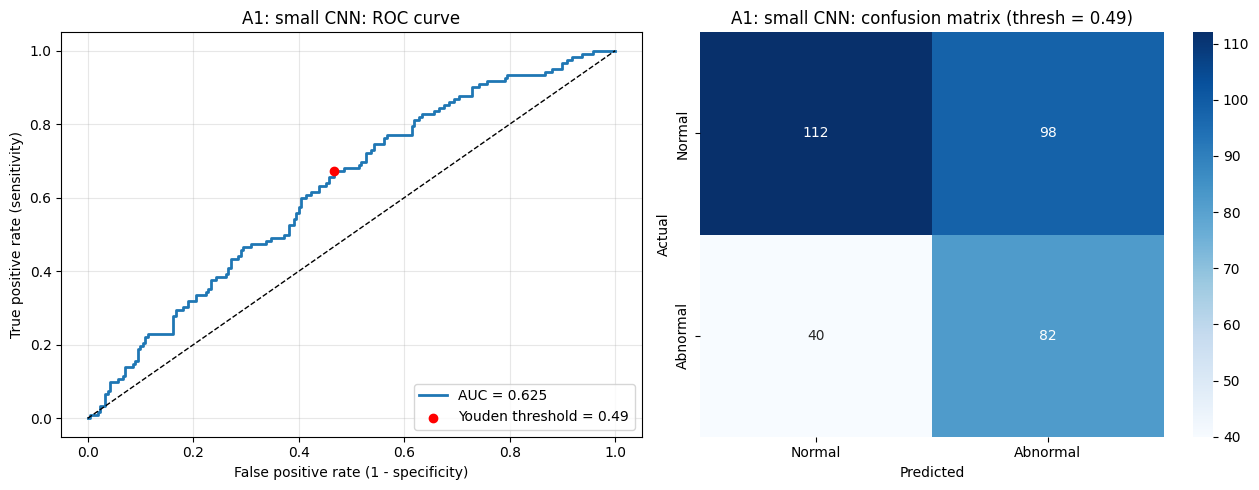

Classification report at Youden threshold (0.49):
              precision    recall  f1-score   support

      Normal       0.74      0.53      0.62       210
    Abnormal       0.46      0.67      0.54       122

    accuracy                           0.58       332
   macro avg       0.60      0.60      0.58       332
weighted avg       0.63      0.58      0.59       332



In [57]:
# ROC curve, confusion matrix, and classification report for A1
per_a1_eval, thresh_a1 = evaluate_experiment(pred_a1, "A1: small CNN")

## 7. Experiment B: colour vs grayscale (after-acid only)

======

B1 repeats the small CNN with more patience (50 max epochs, patience 8), to check whether A1 stopped too early.

B2 converts the after-acid photos to grayscale before training, checking whether colour matters or whether the tissue morphology alone is enough.


In [58]:
print("after-acid photos:", int(is_post.sum()))

pred_post, hist_post = run_cv(build_small_cnn, "B1_small_cnn_post",
                              max_epochs=50, patience=8)
per_post = score(pred_post, "B1 after-acid CNN (patience 8)")
add_result("B1 CNN", "after-acid", "from scratch, patience 8", pred_post)
paired_diff(per_post, per_a1, "B1 (patience 8)", "A1 (patience 6)")


after-acid photos: 1671
fold 0: already done, skipping
fold 1: already done, skipping
fold 2: already done, skipping
fold 3: already done, skipping
fold 4: already done, skipping
B1 after-acid CNN (patience 8): patient AUC 0.622 (95% CI 0.56-0.69) | 332 patients | per-fold [0.69 0.54 0.73 0.58 0.57]
B1 (patience 8) vs A1 (patience 6): -0.003 (95% CI -0.02 to +0.02) -> includes 0


In [59]:
# Convert photos to grayscale using luminance weights
weights = np.array([0.299, 0.587, 0.114], dtype=np.float32)
gray    = (X @ weights).astype(np.uint8)
X_gray  = np.repeat(gray[..., None], 3, axis=3)
del gray
print("grayscale array:", X_gray.shape, X_gray.dtype)

# Temporarily swap X so run_cv uses the grayscale array
X_colour = X
try:
    X = X_gray
    pred_gray_post, _ = run_cv(build_small_cnn, "B2_gray_cnn_post",
                               max_epochs=50, patience=8)
finally:
    X = X_colour  # always restore, even if run_cv raises
del X_gray

per_gray_post = score(pred_gray_post, "B2 after-acid, grayscale CNN")
add_result("B2 CNN grayscale", "after-acid", "grayscale, patience 8", pred_gray_post)
paired_diff(per_gray_post, per_post, "grayscale CNN", "colour CNN (after-acid)")


grayscale array: (3310, 192, 256, 3) uint8
fold 0: already done, skipping
fold 1: already done, skipping
fold 2: already done, skipping
fold 3: already done, skipping
fold 4: already done, skipping
B2 after-acid, grayscale CNN: patient AUC 0.517 (95% CI 0.45-0.59) | 332 patients | per-fold [0.54 0.43 0.52 0.6  0.57]
grayscale CNN vs colour CNN (after-acid): -0.106 (95% CI -0.18 to -0.03) -> excludes 0


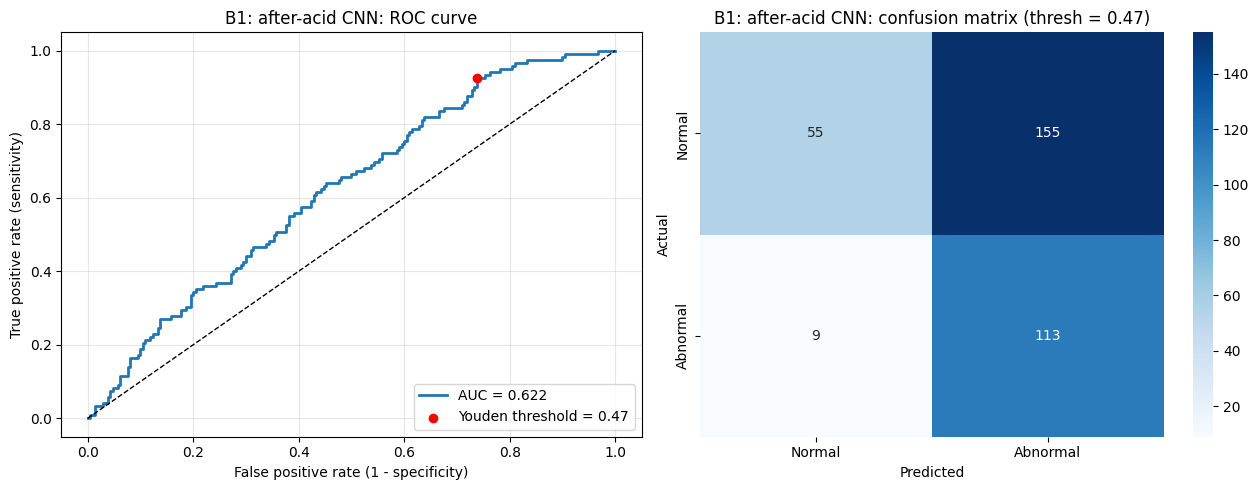

Classification report at Youden threshold (0.47):
              precision    recall  f1-score   support

      Normal       0.86      0.26      0.40       210
    Abnormal       0.42      0.93      0.58       122

    accuracy                           0.51       332
   macro avg       0.64      0.59      0.49       332
weighted avg       0.70      0.51      0.47       332



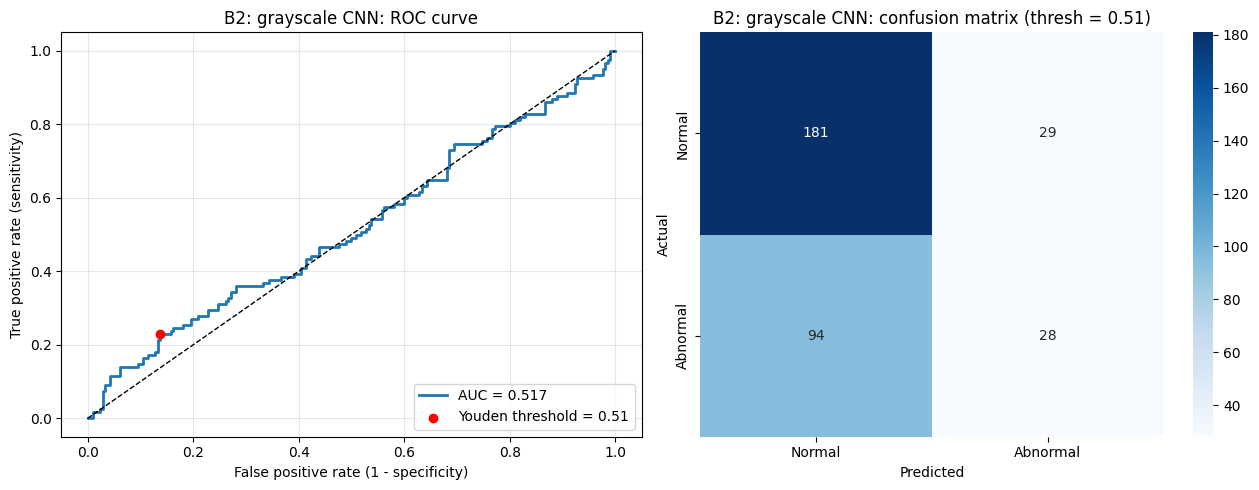

Classification report at Youden threshold (0.51):
              precision    recall  f1-score   support

      Normal       0.66      0.86      0.75       210
    Abnormal       0.49      0.23      0.31       122

    accuracy                           0.63       332
   macro avg       0.57      0.55      0.53       332
weighted avg       0.60      0.63      0.59       332



In [60]:
# ROC curve, confusion matrix, and classification report for B experiments
per_post_eval, thresh_post = evaluate_experiment(pred_post,      "B1: after-acid CNN")
per_gray_eval, thresh_gray = evaluate_experiment(pred_gray_post, "B2: grayscale CNN")


## 8. Experiment T1: frozen transfer features

======

Extract features from four pretrained ImageNet backbones with all weights frozen, then fit a logistic regression head. This is the fastest way to test whether ImageNet features transfer at all to colposcopy images. No GPU needed once the feature files are saved.

Backbones tested: DenseNet121, ResNet50, EfficientNetB0, MobileNetV2.


In [61]:
# Backbone features, computed for the after-acid photos only (rows for other photos stay NaN and are never used).
# If the earlier run already saved features for all photos in DATA_DIR, those are reused: same array, same order.
def feat_path(name):
    old = f"{DATA_DIR}/feats_{name}_192x256.npy"
    new = f"{OUT}/feats_{name}_192x256.npy"
    return old if os.path.exists(old) else new

post_idx = np.where(is_post)[0]
for name, (builder, prep) in backbones.items():
    path = feat_path(name)
    if os.path.exists(path):
        print(name, "already saved, skipping:", path)
        continue
    t0  = time.time()
    net = builder(include_top=False, weights="imagenet",
                  pooling="avg", input_shape=(192, 256, 3))
    chunks = []
    for start in range(0, len(post_idx), 64):
        sel = post_idx[start:start + 64]
        chunks.append(net.predict(prep(X[sel].astype(np.float32)), verbose=0))
    part = np.concatenate(chunks)
    feats = np.full((len(X), part.shape[1]), np.nan, dtype=np.float32)
    feats[post_idx] = part
    np.save(path, feats)
    print(f"{name}: {feats.shape} in {(time.time() - t0) / 60:.1f} min")
    del net, chunks, part, feats
    tf.keras.backend.clear_session()
    gc.collect()


densenet121 already saved, skipping: /content/drive/MyDrive/cervical_v2/feats_densenet121_192x256.npy
resnet50 already saved, skipping: /content/drive/MyDrive/cervical_v2/feats_resnet50_192x256.npy
efficientnetb0 already saved, skipping: /content/drive/MyDrive/cervical_v2/feats_efficientnetb0_192x256.npy
mobilenetv2 already saved, skipping: /content/drive/MyDrive/cervical_v2/feats_mobilenetv2_192x256.npy


In [62]:
# Baseline small-CNN predictions for comparison (after-acid only)
base_path = f"{OUT}/oof_A1_small_cnn_post.npy"
base = patient_table(np.load(base_path)) if os.path.exists(base_path) else None

for name in ["densenet121", "resnet50", "efficientnetb0", "mobilenetv2"]:
    F = np.load(feat_path(name))
    assert len(F) == len(meta)
    assert not np.isnan(F[is_post]).any(), "missing features for some after-acid photos"
    pred = linear_cv(F, everyone)
    add_result(f"T1 {name} frozen", "after-acid", "logistic regression C=0.01", pred)
    if base is not None:
        paired_diff(patient_table(pred), base, f"{name} frozen", "small CNN")

show_results()


densenet121 frozen vs small CNN: -0.115 (95% CI -0.19 to -0.04) -> excludes 0
resnet50 frozen vs small CNN: -0.065 (95% CI -0.14 to +0.01) -> includes 0
efficientnetb0 frozen vs small CNN: -0.105 (95% CI -0.17 to -0.04) -> excludes 0
mobilenetv2 frozen vs small CNN: -0.058 (95% CI -0.13 to +0.01) -> includes 0
              experiment     photos                      notes  patient_auc  ci_low  ci_high  worst_fold
            A1 small CNN after-acid   from scratch, patience 6        0.625   0.565    0.688       0.532
                  B1 CNN after-acid   from scratch, patience 8        0.622   0.562    0.685       0.540
   T1 mobilenetv2 frozen after-acid logistic regression C=0.01        0.567   0.507    0.633       0.403
      T1 resnet50 frozen after-acid logistic regression C=0.01        0.560   0.498    0.623       0.497
T1 efficientnetb0 frozen after-acid logistic regression C=0.01        0.520   0.460    0.579       0.394
        B2 CNN grayscale after-acid      grayscale, patien

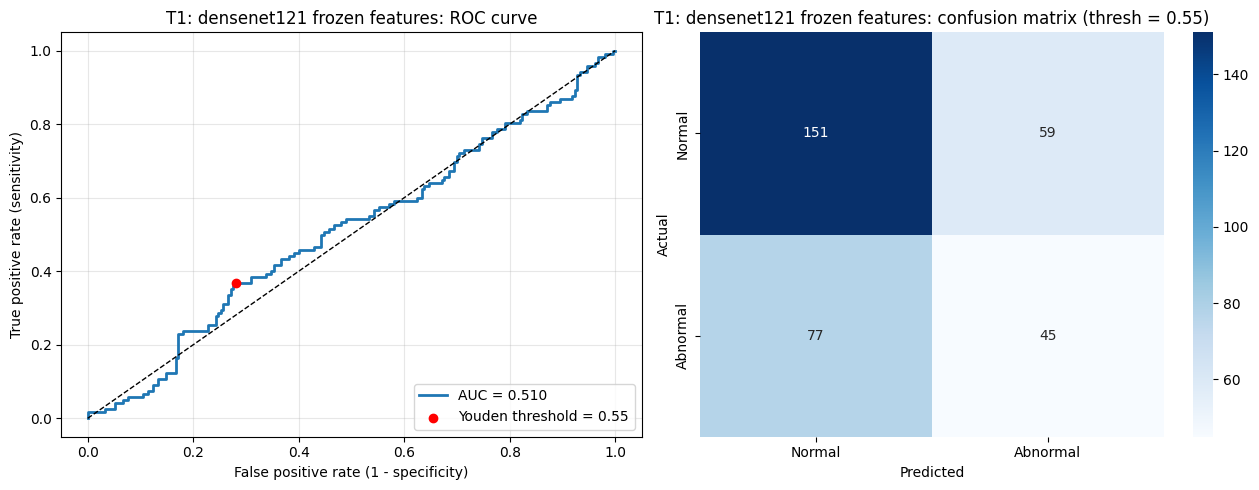

Classification report at Youden threshold (0.55):
              precision    recall  f1-score   support

      Normal       0.66      0.72      0.69       210
    Abnormal       0.43      0.37      0.40       122

    accuracy                           0.59       332
   macro avg       0.55      0.54      0.54       332
weighted avg       0.58      0.59      0.58       332



In [63]:
# Evaluate the best T1 result
# Update the name below to whichever backbone performed best
best_t1_name = "densenet121"  # adjust as needed

# T1 predictions are not saved as oof files; use linear_cv to reproduce them
pred_t1_all = linear_cv(np.load(feat_path(best_t1_name)), everyone)
per_t1, thresh_t1 = evaluate_experiment(pred_t1_all, f"T1: {best_t1_name} frozen features")


## 9. Experiments T2 and T3: fine-tuning

======

Warm up the dense head for a few epochs with the backbone frozen, then unfreeze the last N backbone layers and continue training at a lower learning rate.

T2 unfroze the last 60 layers on MobileNetV2. T3 ran all four backbones with different unfreeze depths.

The training logs reveal the problem: training AUC reaches 0.95 while validation AUC stays around 0.55. That gap is what T4 is designed to address.

In this copy every run uses after-acid photos only.


In [64]:
# T2: MobileNetV2, last 60 layers unfrozen
pred_t2, hist_t2 = run_cv_ft(
    backbone      = "mobilenetv2",
    name          = "T2_mobilenetv2_post",
    unfreeze_last = 60,
)
per_t2 = score(pred_t2, "T2 MobileNetV2 fine-tuned, after-acid photos")
add_result("T2 MobileNetV2", "after-acid", "last 60 layers unfrozen", pred_t2)
paired_diff(per_t2, per_a1, "T2 MobileNetV2", "A1 baseline")

fold 0: already done, skipping
fold 1: already done, skipping
fold 2: already done, skipping
fold 3: already done, skipping
fold 4: already done, skipping
T2 MobileNetV2 fine-tuned, after-acid photos: patient AUC 0.552 (95% CI 0.49-0.62) | 332 patients | per-fold [0.66 0.68 0.47 0.53 0.54]
T2 MobileNetV2 vs A1 baseline: -0.073 (95% CI -0.16 to +0.01) -> includes 0


In [65]:
# T3: all four backbones with different unfreeze depths (after-acid photos only)
RUNS3 = [
    ("mobilenetv2",    20),
    ("densenet121",    60),
    ("resnet50",        4),
    ("efficientnetb0", 20),
]

for backbone, n_unfreeze in RUNS3:
    print(f"======= {backbone} | last {n_unfreeze} layers =======")
    pred, _ = run_cv_ft(
        backbone      = backbone,
        name          = f"T3_{backbone}_post_u{n_unfreeze}",
        unfreeze_last = n_unfreeze,
    )
    add_result(f"T3 {backbone}", "after-acid", f"last {n_unfreeze} layers", pred)
    paired_diff(patient_table(pred), per_a1,
                f"{backbone} u{n_unfreeze}", "A1 baseline")

show_results()


======= mobilenetv2 | last 20 layers =======
fold 0: already done, skipping
fold 1: already done, skipping
fold 2: already done, skipping
fold 3: already done, skipping
fold 4: already done, skipping
mobilenetv2 u20 vs A1 baseline: -0.058 (95% CI -0.14 to +0.02) -> includes 0
======= densenet121 | last 60 layers =======
fold 0: already done, skipping
fold 1: already done, skipping
fold 2: already done, skipping
fold 3: already done, skipping
fold 4: already done, skipping
densenet121 u60 vs A1 baseline: -0.061 (95% CI -0.14 to +0.02) -> includes 0
======= resnet50 | last 4 layers =======
fold 0: already done, skipping
fold 1: already done, skipping
fold 2: already done, skipping
fold 3: already done, skipping
fold 4: already done, skipping
resnet50 u4 vs A1 baseline: -0.056 (95% CI -0.14 to +0.02) -> includes 0
======= efficientnetb0 | last 20 layers =======
fold 0: already done, skipping
fold 1: already done, skipping
fold 2: already done, skipping
fold 3: already done, skipping
fold 

In [66]:
# Training curves for T2 -- this is where the train/val gap is most visible
# hist_t2 contains per-fold histories from the run above
plot_training_curves(hist_t2, "T2: MobileNetV2 fine-tuned")

No training histories available (all folds loaded from disk).


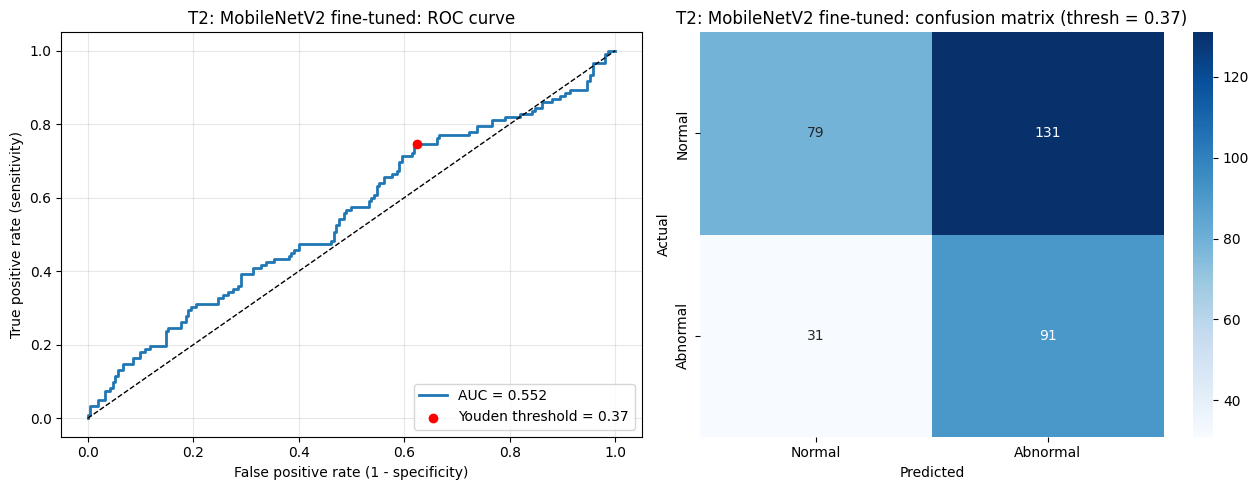

Classification report at Youden threshold (0.37):
              precision    recall  f1-score   support

      Normal       0.72      0.38      0.49       210
    Abnormal       0.41      0.75      0.53       122

    accuracy                           0.51       332
   macro avg       0.56      0.56      0.51       332
weighted avg       0.60      0.51      0.51       332



In [67]:
# ROC curve, confusion matrix, and classification report for T2
per_t2_eval, thresh_t2 = evaluate_experiment(pred_t2, "T2: MobileNetV2 fine-tuned")

## 10. Experiment T4: regularized fine-tuning

======

Three changes from T3 to address the overfitting:

1. AdamW with weight decay 1e-4 instead of plain Adam
2. Label smoothing 0.1 added to the binary crossentropy loss
3. Dropout raised to 0.5

The augmentation also gets stronger: vertical flips added, rotation and zoom ranges doubled.

We use the same backbone (MobileNetV2) and unfreeze depth (20 layers) as the best T3 run so the comparison is clean. This section needs a GPU run.


In [68]:
# T4: MobileNetV2 with regularization
# Label smoothing slightly penalizes confident predictions and discourages the model
# from memorizing training examples

label_smooth_loss = tf.keras.losses.BinaryCrossentropy(label_smoothing=0.1)

pred_t4, hist_t4 = run_cv_ft(
    backbone      = "mobilenetv2",
    name          = "T4_mobilenetv2_post_reg",
    unfreeze_last = 20,
    dropout       = 0.5,              # stronger dropout vs T3 (0.3)
    aug_fn        = augment_block_strong,
    weight_decay  = 1e-4,             # AdamW weight decay
    loss          = label_smooth_loss,
    lr_head       = 1e-3,
    lr_ft         = 5e-5,
    patience      = 10,               # a bit more patience since regularization slows convergence
)

per_t4 = score(pred_t4, "T4 MobileNetV2 regularized, after-acid photos")
add_result("T4 MobileNetV2 reg", "after-acid", "AdamW + label smoothing + dropout 0.5", pred_t4)
paired_diff(per_t4, per_t2,  "T4 regularized", "T2 fine-tuned (60 layers)")
paired_diff(per_t4, per_a1,  "T4 regularized", "A1 baseline")

fold 0: already done, skipping
fold 1: already done, skipping
fold 2: already done, skipping
fold 3: already done, skipping
fold 4: already done, skipping
T4 MobileNetV2 regularized, after-acid photos: patient AUC 0.563 (95% CI 0.50-0.63) | 332 patients | per-fold [0.6  0.67 0.45 0.49 0.6 ]
T4 regularized vs T2 fine-tuned (60 layers): +0.011 (95% CI -0.04 to +0.06) -> includes 0
T4 regularized vs A1 baseline: -0.062 (95% CI -0.14 to +0.01) -> includes 0


No training histories available (all folds loaded from disk).


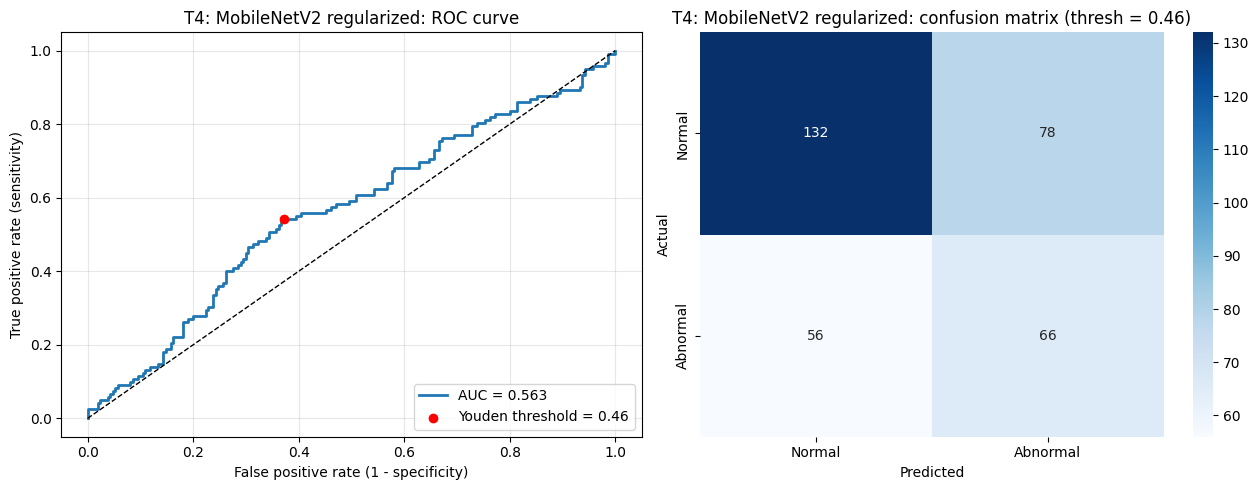

Classification report at Youden threshold (0.46):
              precision    recall  f1-score   support

      Normal       0.70      0.63      0.66       210
    Abnormal       0.46      0.54      0.50       122

    accuracy                           0.60       332
   macro avg       0.58      0.58      0.58       332
weighted avg       0.61      0.60      0.60       332



In [69]:
# Training curves: expect narrower train/val gap vs T2
plot_training_curves(hist_t4, "T4: MobileNetV2 regularized")

# ROC curve, confusion matrix, and classification report
per_t4_eval, thresh_t4 = evaluate_experiment(pred_t4, "T4: MobileNetV2 regularized")

## 11. Final results

======

All experiments side by side. The per-fold variance chart matters as much as the mean AUC at this dataset size: 332 patients gives wide confidence intervals, and a model with AUC 0.65 but high fold variance is not clearly better than one at 0.62 with low variance.

The sensitivity/specificity table uses the Youden threshold computed separately per model.


In [70]:
# Load any saved predictions not already in memory and add to results table
def add_if_exists(fname, exp_name, photos, notes, keep_mask=None):
    path = f"{OUT}/oof_{fname}.npy"
    if not os.path.exists(path):
        print(f"skipping {exp_name}: file not found")
        return
    pred = np.load(path)
    add_result(exp_name, photos, notes, pred, keep_mask)

# Clear existing results and reload to avoid duplicates
results.clear()

# keep_mask=None means `everyone`, which is the after-acid photos in this notebook
add_if_exists("A1_small_cnn_post",              "A1 small CNN",          "after-acid", "from scratch, patience 6")
add_if_exists("B1_small_cnn_post",              "B1 small CNN",          "after-acid", "from scratch, patience 8")
add_if_exists("B2_gray_cnn_post",               "B2 grayscale",          "after-acid", "grayscale")
add_if_exists("T2_mobilenetv2_post",            "T2 MobileNetV2",        "after-acid", "60 layers FT")
add_if_exists("T3_mobilenetv2_post_u20",        "T3 MobileNetV2 u20",    "after-acid", "20 layers FT")
add_if_exists("T3_densenet121_post_u60",        "T3 DenseNet121 u60",    "after-acid", "60 layers FT")
add_if_exists("T3_resnet50_post_u4",            "T3 ResNet50 u4",        "after-acid", "4 layers FT")
add_if_exists("T3_efficientnetb0_post_u20",     "T3 EfficientNetB0 u20", "after-acid", "20 layers FT")
add_if_exists("T4_mobilenetv2_post_reg",        "T4 MobileNetV2 reg",    "after-acid", "AdamW+LS+drop0.5")

show_results()


           experiment     photos                    notes  patient_auc  ci_low  ci_high  worst_fold
         A1 small CNN after-acid from scratch, patience 6        0.625   0.565    0.688       0.532
         B1 small CNN after-acid from scratch, patience 8        0.622   0.562    0.685       0.540
T3 EfficientNetB0 u20 after-acid             20 layers FT        0.576   0.511    0.638       0.417
       T3 ResNet50 u4 after-acid              4 layers FT        0.569   0.506    0.630       0.366
   T3 MobileNetV2 u20 after-acid             20 layers FT        0.567   0.501    0.632       0.473
   T3 DenseNet121 u60 after-acid             60 layers FT        0.564   0.499    0.625       0.416
   T4 MobileNetV2 reg after-acid         AdamW+LS+drop0.5        0.563   0.501    0.626       0.450
       T2 MobileNetV2 after-acid             60 layers FT        0.552   0.486    0.619       0.469
         B2 grayscale after-acid                grayscale        0.517   0.452    0.588       0.428


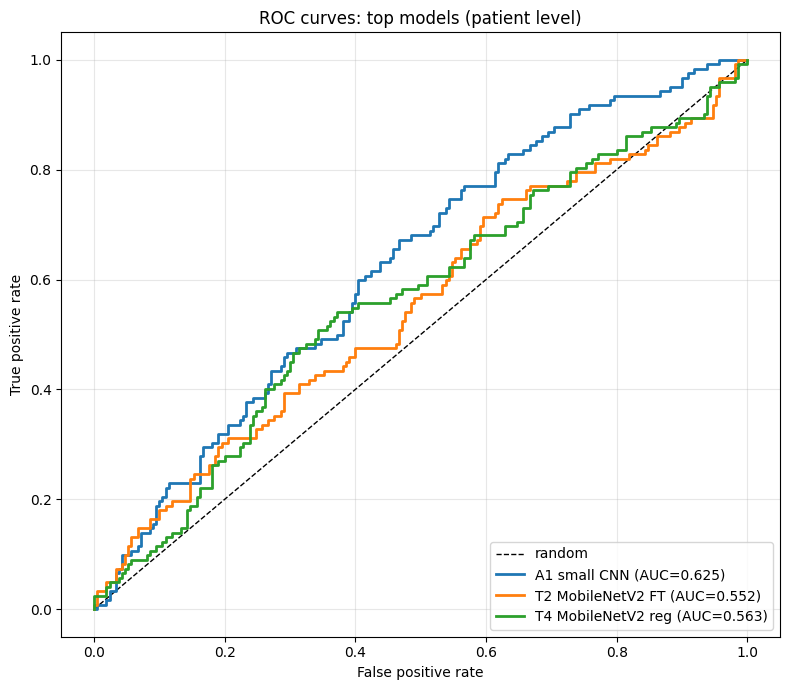

In [71]:
# Overlay ROC curves for the main experiments
fig, ax = plt.subplots(figsize=(8, 7))
ax.plot([0, 1], [0, 1], "k--", lw=1, label="random")

top_models = {
    "A1 small CNN":       ("A1_small_cnn_post",           everyone),
    "T2 MobileNetV2 FT":  ("T2_mobilenetv2_post",     everyone),
    "T4 MobileNetV2 reg": ("T4_mobilenetv2_post_reg",  everyone),
}

for label, (fname, keep_mask) in top_models.items():
    path = f"{OUT}/oof_{fname}.npy"
    if not os.path.exists(path):
        continue
    pred = np.load(path)
    per  = patient_table(pred, keep_mask)
    fpr_m, tpr_m, _ = roc_curve(per["y"], per["p"])
    ax.plot(fpr_m, tpr_m, lw=2, label=f"{label} (AUC={auc(fpr_m, tpr_m):.3f})")

ax.set_xlabel("False positive rate")
ax.set_ylabel("True positive rate")
ax.set_title("ROC curves: top models (patient level)")
ax.legend(loc="lower right")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [72]:
# Sensitivity and specificity at the Youden threshold per model
summary_rows = []

model_files = [
    ("A1 small CNN",        "A1_small_cnn_post",       everyone),
    ("B1 small CNN",        "B1_small_cnn_post",       everyone),
    ("B2 grayscale",        "B2_gray_cnn_post",        everyone),
    ("T2 MobileNetV2",      "T2_mobilenetv2_post",     everyone),
    ("T3 MobileNetV2 u20",  "T3_mobilenetv2_post_u20", everyone),
    ("T4 MobileNetV2 reg",  "T4_mobilenetv2_post_reg", everyone),
]

for exp_name, fname, keep_mask in model_files:
    path = f"{OUT}/oof_{fname}.npy"
    if not os.path.exists(path):
        continue
    pred = np.load(path)
    per  = patient_table(pred, keep_mask)
    fpr_m, tpr_m, thresholds = roc_curve(per["y"], per["p"])
    j_idx = int(np.argmax(tpr_m - fpr_m))

    summary_rows.append({
        "model":       exp_name,
        "AUC":         round(auc(fpr_m, tpr_m), 3),
        "sensitivity": round(float(tpr_m[j_idx]), 3),
        "specificity": round(float(1 - fpr_m[j_idx]), 3),
        "threshold":   round(float(thresholds[j_idx]), 3),
        "patients":    len(per),
    })

summary = pd.DataFrame(summary_rows).sort_values("AUC", ascending=False)
print(summary.to_string(index=False))


             model   AUC  sensitivity  specificity  threshold  patients
      A1 small CNN 0.625        0.672        0.533      0.487       332
      B1 small CNN 0.622        0.926        0.262      0.474       332
T3 MobileNetV2 u20 0.567        0.361        0.781      0.524       332
T4 MobileNetV2 reg 0.563        0.541        0.629      0.458       332
    T2 MobileNetV2 0.552        0.746        0.376      0.375       332
      B2 grayscale 0.517        0.230        0.862      0.509       332


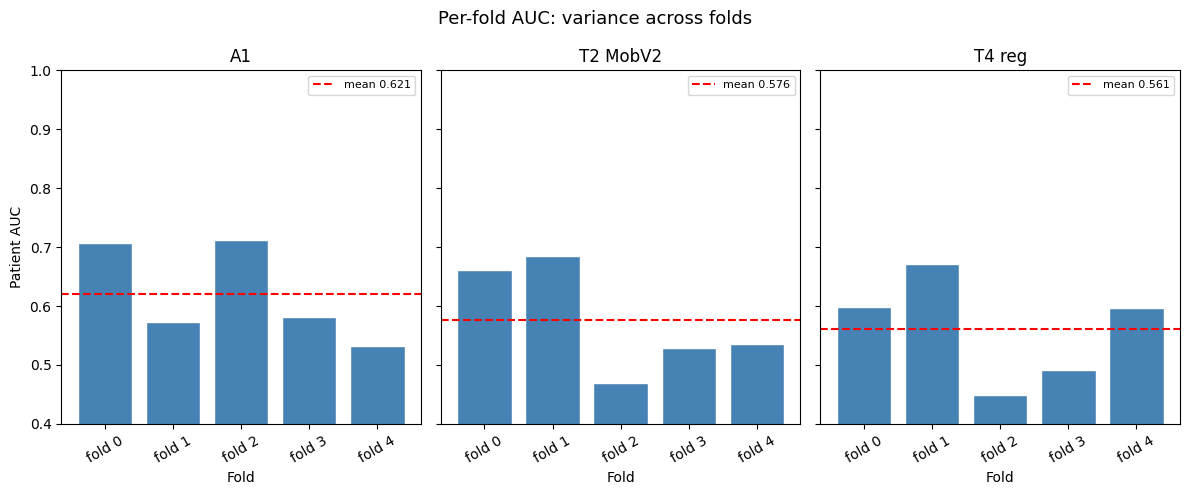

In [73]:
# Per-fold AUC bar chart: shows how stable each model is across folds
fold_aucs = {}

chart_models = [
    ("A1",        "A1_small_cnn_post",          everyone),
    ("T2 MobV2",  "T2_mobilenetv2_post",    everyone),
    ("T4 reg",    "T4_mobilenetv2_post_reg", everyone),
]

for exp_name, fname, keep_mask in chart_models:
    path = f"{OUT}/oof_{fname}.npy"
    if not os.path.exists(path):
        continue
    pred = np.load(path)
    per  = patient_table(pred, keep_mask)
    fold_aucs[exp_name] = [roc_auc_score(g["y"], g["p"])
                           for _, g in per.groupby("fold")]

n_models = len(fold_aucs)
if n_models == 0:
    print("No prediction files found.")
else:
    fig, axes = plt.subplots(1, n_models, figsize=(4 * n_models, 5), sharey=True)
    if n_models == 1:
        axes = [axes]

    for ax, (name, aucs) in zip(axes, fold_aucs.items()):
        folds = [f"fold {i}" for i in range(len(aucs))]
        ax.bar(folds, aucs, color="steelblue", edgecolor="white")
        ax.axhline(np.mean(aucs), color="red", lw=1.5, linestyle="--",
                   label=f"mean {np.mean(aucs):.3f}")
        ax.set_ylim(0.4, 1.0)
        ax.set_title(name)
        ax.set_xlabel("Fold")
        ax.legend(fontsize=8)
        ax.tick_params(axis="x", rotation=30)

    axes[0].set_ylabel("Patient AUC")
    plt.suptitle("Per-fold AUC: variance across folds", fontsize=13)
    plt.tight_layout()
    plt.show()

## 12. App export: ensemble, Grad-CAM, and `predict_with_explanation`

======

The app model is the five fold models from A1 (the small CNN), averaged. Nothing is retrained on all patients.

Two cautions that apply to everything below:

- **Do not score the ensemble on the training photos.** Every photo was in the training data of four of the five fold models, so the AUC would be inflated. The honest performance number stays the out-of-fold patient AUC from section 6.
- **The heatmap is a review aid, not a lesion location.** With patient AUC around 0.6 it shows what the model used, which can include speculum edges or tools. The sanity checks near the end of this section test that.
- **After-acid photos only.** This model never saw before-acid photos during training, so the app should only accept after-acid photos. Scores for before-acid photos are meaningless.


In [74]:
# Load the five fold models and check they behave like the ones that were trained
MODEL_DIR = f"{OUT}/models/A1_small_cnn_post"
fold_models = []
for f in range(5):
    p = f"{MODEL_DIR}/fold{f}.keras"
    assert os.path.exists(p), f"missing {p}: rerun A1 with save_models=True"
    fold_models.append(tf.keras.models.load_model(p))
print("loaded", len(fold_models), "fold models |", f"{fold_models[0].count_params():,} parameters each")

# Each fold model must reproduce its own out-of-fold predictions (after-acid photos of that fold)
for f, m in enumerate(fold_models):
    idx = np.where(is_post & (meta["fold"].values == f))[0]
    p = m.predict(X[idx], batch_size=64, verbose=0).ravel()
    print(f"fold {f}: max |difference| vs saved out-of-fold predictions = {np.abs(p - pred_a1[idx]).max():.2e}")

# Reference numbers for the app. Patient-level is the validated one.
print(f"\npatient-level AUC (validated): {roc_auc_score(per_a1['y'], per_a1['p']):.3f}")
print(f"photo-level AUC (single photo): {roc_auc_score(y[is_post], pred_a1[is_post]):.3f}")


loaded 5 fold models | 23,649 parameters each
fold 0: max |difference| vs saved out-of-fold predictions = 0.00e+00
fold 1: max |difference| vs saved out-of-fold predictions = 0.00e+00
fold 2: max |difference| vs saved out-of-fold predictions = 0.00e+00
fold 3: max |difference| vs saved out-of-fold predictions = 0.00e+00
fold 4: max |difference| vs saved out-of-fold predictions = 0.00e+00

patient-level AUC (validated): 0.625
photo-level AUC (single photo): 0.608


In [75]:
# Preprocessing for new photos. Must be identical to training (section 3).
def preprocess_photo(photo):
    """Path or PIL image -> (model input 192x256x3 uint8, original RGB array).
    Steps: RGB, require 640x480, zero the timestamp patch, LANCZOS resize."""
    im = photo if isinstance(photo, Image.Image) else Image.open(photo)
    im = im.convert("RGB")
    if im.size != (640, 480):
        raise ValueError(f"unexpected size {im.size}: the timestamp mask assumes 640x480 photos")
    original = np.array(im)
    a = original.copy()
    a[:PATCH_H, :PATCH_W] = 0
    small = np.array(Image.fromarray(a).resize((W, H), Image.LANCZOS))
    return small, original

# The app path must reproduce the training array exactly
rng = np.random.default_rng(0)
for i in rng.choice(len(meta), 20, replace=False):
    small, _ = preprocess_photo(meta["image_path"].iloc[i])
    assert np.array_equal(small, X[i]), f"preprocessing differs from training for photo {i}"
print("preprocess_photo matches the training array on 20 random photos")


preprocess_photo matches the training array on 20 random photos


In [76]:
# Grad-CAM for the small CNN
# Target layer: the last Conv2D (output 44 x 60). The network is conv -> pool -> global average pool -> dense,
# so this layer holds the last spatial map before it is averaged away.
# The map explains the PREDICTED class: for a photo scored as abnormal it shows regions that pushed the score up,
# for a photo scored as normal it shows regions that pushed it down. (Explaining "abnormal" only would give an
# empty map for every normal-leaning photo.)

THRESHOLD = float(thresh_a1)    # Youden point from the out-of-fold predictions (section 6). Provisional.

def _last_conv(model):
    for layer in reversed(model.layers):
        if isinstance(layer, tf.keras.layers.Conv2D):
            return layer
    raise ValueError("no Conv2D layer found")

def make_grad_model(model):
    return tf.keras.Model(model.input, [_last_conv(model).output, model.output])

GRAD_MODELS = [make_grad_model(m) for m in fold_models]

def _cam_batch(gm, x, sign=1):
    x = tf.convert_to_tensor(np.ascontiguousarray(x), tf.float32)
    with tf.GradientTape() as tape:
        conv, prob = gm(x, training=False)
        target = sign * prob[:, 0]
    grads   = tape.gradient(target, conv)
    weights = tf.reduce_mean(grads, axis=(1, 2), keepdims=True)
    cam     = tf.nn.relu(tf.reduce_sum(weights * conv, axis=-1))
    return cam.numpy()

def _unit(c):
    return c / (c.max() + 1e-8)

def ensemble_prob(small, grad_models=None):
    """Mean probability over the fold models for one 192x256x3 uint8 photo (un-flipped, as validated)."""
    x = small[None].astype(np.float32)
    return float(np.mean([gm(x, training=False)[1].numpy()[0, 0] for gm in (grad_models or GRAD_MODELS)]))

def gradcam_ensemble(small, grad_models, flip=True, sign=1):
    """Heatmap (192x256, values 0-1) for one photo. sign=+1 explains 'abnormal', sign=-1 explains 'normal'.
    Averaged over the models and, if flip=True, over the mirrored photo as well."""
    x = small[None].astype(np.float32)
    cams = []
    for gm in grad_models:
        cams.append(_unit(_cam_batch(gm, x, sign)[0]))
        if flip:
            cam_f = _cam_batch(gm, x[:, :, ::-1, :], sign)[0]
            cams.append(_unit(cam_f[:, ::-1]))
    cam = np.mean(cams, axis=0)
    cam = tf.image.resize(cam[..., None], (H, W), method="bilinear").numpy()[..., 0]
    cam[: round(H * PATCH_H / 480), : round(W * PATCH_W / 640)] = 0   # blanked timestamp area carries no information
    return _unit(cam)

def overlay_heatmap(original, cam, alpha=0.5):
    """Blend the heatmap onto the original photo (uint8 RGB). Cool areas stay see-through."""
    h, w = original.shape[:2]
    big = np.array(Image.fromarray(cam.astype(np.float32), mode="F").resize((w, h), Image.BILINEAR))
    big = np.clip(big, 0, 1)[..., None]
    color = plt.get_cmap("jet")(big[..., 0])[..., :3] * 255
    a = alpha * big
    return (original * (1 - a) + color * a).astype(np.uint8)


In [77]:
# The function the app calls
DISCLAIMER = ("Experimental research prototype, not validated for clinical use. Use after-acid photos only. "
              "The highlighted areas show what the model used. They are a review aid, not a lesion location.")

def predict_with_explanation(photos):
    """photos: one path/PIL image, or a list of them (all after-acid photos of one patient).
    Score = mean probability over photos and over the 5 fold models, the same way patient AUC was computed.
    The heatmaps explain the predicted class (see section note)."""
    if not isinstance(photos, (list, tuple)):
        photos = [photos]
    smalls, originals = zip(*[preprocess_photo(ph) for ph in photos])
    score = float(np.mean([ensemble_prob(s) for s in smalls]))
    label = "abnormal" if score >= THRESHOLD else "normal"
    sign  = 1 if label == "abnormal" else -1
    overlays = [overlay_heatmap(o, gradcam_ensemble(s, GRAD_MODELS, flip=True, sign=sign))
                for s, o in zip(smalls, originals)]
    return {
        "label":     label,
        "score":     round(score, 4),
        "threshold": round(THRESHOLD, 4),
        "heatmap":   overlays,          # one uint8 RGB overlay (480x640x3) per input photo, same order
        "note":      f"{DISCLAIMER} Highlighted areas supported the '{label}' score.",
    }


/tmp/ipykernel_772/2108768525.py:57: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  big = np.array(Image.fromarray(cam.astype(np.float32), mode="F").resize((w, h), Image.BILINEAR))


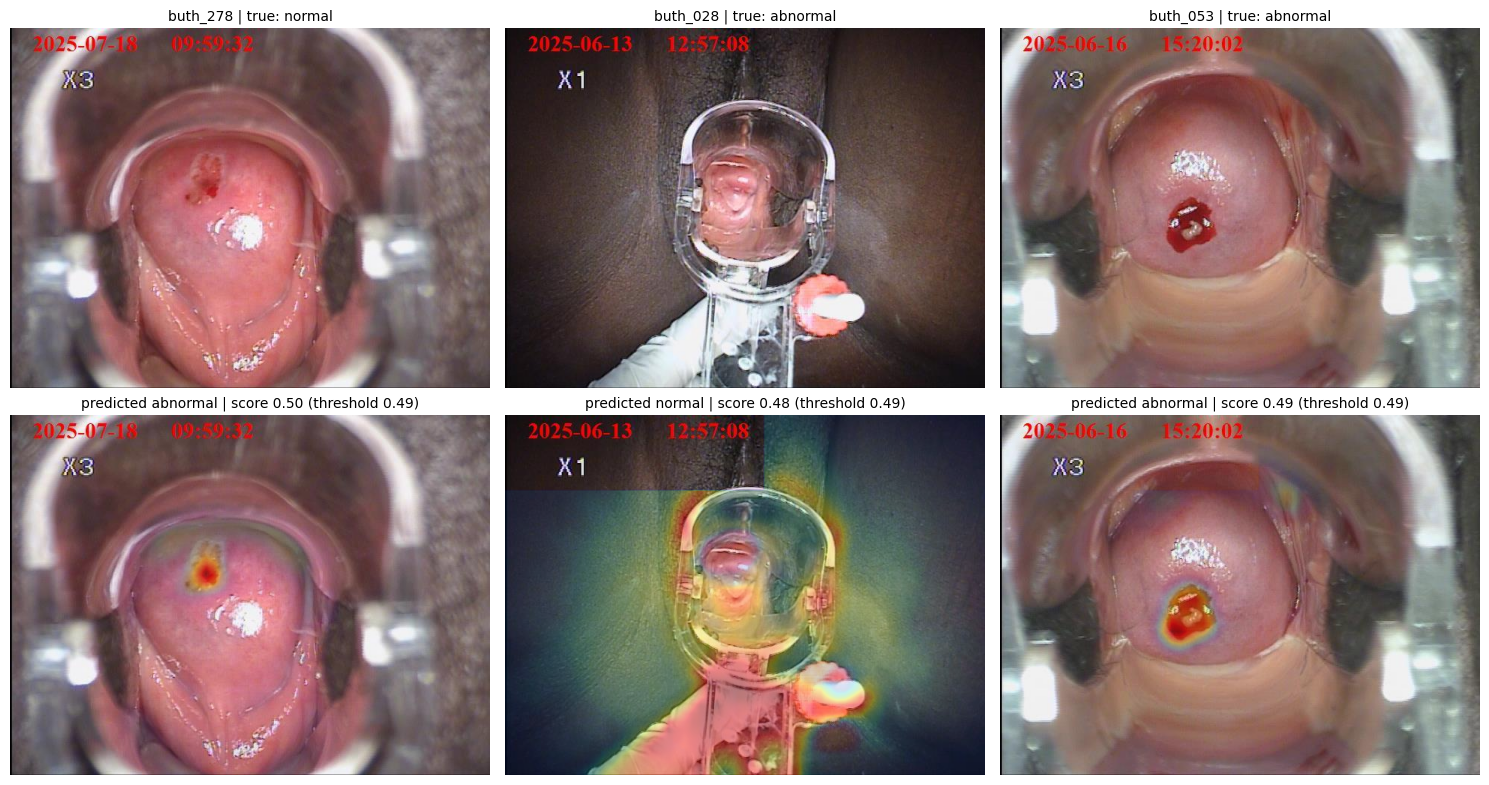

{'label': 'abnormal', 'score': 0.4919, 'threshold': 0.4866, 'heatmap': '1 image(s) (480, 640, 3)', 'note': "Experimental research prototype, not validated for clinical use. Use after-acid photos only. The highlighted areas show what the model used. They are a review aid, not a lesion location. Highlighted areas supported the 'abnormal' score."}


In [78]:
# Smoke test: three photos, original next to heatmap. True labels are shown here for checking only.
rng = np.random.default_rng(3)
picks = [int(rng.choice(np.where((meta["label"].values == lab) & is_post)[0])) for lab in (0, 1, 1)]
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for col, i in enumerate(picks):
    out = predict_with_explanation(meta["image_path"].iloc[i])
    axes[0, col].imshow(Image.open(meta["image_path"].iloc[i])); axes[0, col].axis("off")
    axes[0, col].set_title(f"{meta['patient_id'].iloc[i]} | true: {['normal','abnormal'][meta['label'].iloc[i]]}", fontsize=10)
    axes[1, col].imshow(out["heatmap"][0]); axes[1, col].axis("off")
    axes[1, col].set_title(f"predicted {out['label']} | score {out['score']:.2f} (threshold {out['threshold']:.2f})", fontsize=10)
plt.tight_layout(); plt.show()
print({k: (v if k != "heatmap" else f"{len(v)} image(s) {v[0].shape}") for k, v in out.items()})


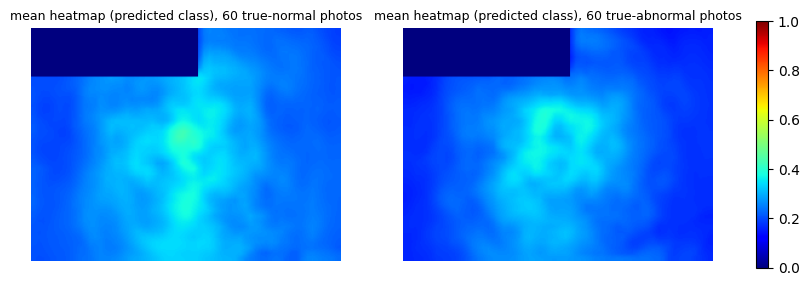

rank correlation, fold-0 model vs fold-1 model:        0.47
rank correlation, fold-0 model vs random-weights model: -0.13
If the second number is close to the first, the heatmap mostly reflects image structure, not learned features.


In [79]:
# Sanity checks: does the heatmap reflect what the model learned?
from scipy.stats import spearmanr

rng  = np.random.default_rng(7)
idx0 = rng.choice(np.where((meta["label"].values == 0) & is_post)[0], 60, replace=False)
idx1 = rng.choice(np.where((meta["label"].values == 1) & is_post)[0], 60, replace=False)

# (1) Average heatmap per class: a bright rim or one fixed corner suggests edges/tools, not tissue
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
mean_cams = {}
for ax, idx, name in zip(axes, (idx0, idx1), ("normal", "abnormal")):
    cams = [gradcam_ensemble(X[i], GRAD_MODELS, flip=False,
                             sign=1 if ensemble_prob(X[i]) >= THRESHOLD else -1) for i in idx]
    mean_cams[name] = np.mean(cams, axis=0)
    im = ax.imshow(mean_cams[name], cmap="jet", vmin=0, vmax=1); ax.axis("off")
    ax.set_title(f"mean heatmap (predicted class), 60 true-{name} photos", fontsize=9)
plt.colorbar(im, ax=axes, shrink=0.8); plt.show()

# (2) Do trained models agree with each other more than with a randomly initialised network?
rand_gm = make_grad_model(build_small_cnn())
agree, vs_rand = [], []
for i in np.concatenate([idx0[:20], idx1[:20]]):
    sg = 1 if ensemble_prob(X[i]) >= THRESHOLD else -1
    c0 = gradcam_ensemble(X[i], [GRAD_MODELS[0]], flip=False, sign=sg)
    c1 = gradcam_ensemble(X[i], [GRAD_MODELS[1]], flip=False, sign=sg)
    cr = gradcam_ensemble(X[i], [rand_gm],        flip=False, sign=sg)
    agree.append(spearmanr(c0.ravel(), c1.ravel())[0])
    vs_rand.append(spearmanr(c0.ravel(), cr.ravel())[0])
print(f"rank correlation, fold-0 model vs fold-1 model:        {np.nanmean(agree):.2f}")
print(f"rank correlation, fold-0 model vs random-weights model: {np.nanmean(vs_rand):.2f}")
print("If the second number is close to the first, the heatmap mostly reflects image structure, not learned features.")


In [80]:
# Save the export settings next to the models so the backend uses exactly the same values
import json
config = {
    "model": "A1 small CNN trained on after-acid photos only, mean of 5 fold models",
    "files": [f"fold{f}.keras" for f in range(5)],
    "input": {"height": H, "width": W, "channels": 3,
              "values": "raw 0-255 RGB; Rescaling is inside the model",
              "source_photo_size": [640, 480],
              "photo_type": "after-acid (post) photos only; before-acid photos were not used and are not supported"},
    "timestamp_mask": {"rows_px": PATCH_H, "cols_px": PATCH_W,
                       "fraction_of_height": round(PATCH_H / 480, 3),
                       "fraction_of_width": round(PATCH_W / 640, 3),
                       "resize": "LANCZOS, applied after zeroing"},
    "aggregation": "probability averaged over the 5 models, then over a patient's photos",
    "threshold": round(THRESHOLD, 4),
    "threshold_note": "Youden point on the same out-of-fold predictions it was chosen from, so sensitivity/specificity are optimistic. Provisional.",
    "validation": {"patient_auc": round(float(roc_auc_score(per_a1["y"], per_a1["p"])), 3),
                   "bootstrap_ci_95": [round(float(v), 3) for v in auc_ci(per_a1)],
                   "design": "5-fold cross-validation grouped by patient, after-acid photos only, one device"},
    "gradcam": {"layer": "last Conv2D (44x60)", "explains": "predicted class (sign of the target flips for normal)", "flip_averaged": True, "timestamp_area_blanked": True},
    "status": "unvalidated research prototype",
}
with open(f"{MODEL_DIR}/config.json", "w") as fh:
    json.dump(config, fh, indent=2)
print(json.dumps(config, indent=2))


{
  "model": "A1 small CNN trained on after-acid photos only, mean of 5 fold models",
  "files": [
    "fold0.keras",
    "fold1.keras",
    "fold2.keras",
    "fold3.keras",
    "fold4.keras"
  ],
  "input": {
    "height": 192,
    "width": 256,
    "channels": 3,
    "values": "raw 0-255 RGB; Rescaling is inside the model",
    "source_photo_size": [
      640,
      480
    ],
    "photo_type": "after-acid (post) photos only; before-acid photos were not used and are not supported"
  },
  "timestamp_mask": {
    "rows_px": 100,
    "cols_px": 345,
    "fraction_of_height": 0.208,
    "fraction_of_width": 0.539,
    "resize": "LANCZOS, applied after zeroing"
  },
  "aggregation": "probability averaged over the 5 models, then over a patient's photos",
  "threshold": 0.4866,
  "threshold_note": "Youden point on the same out-of-fold predictions it was chosen from, so sensitivity/specificity are optimistic. Provisional.",
  "validation": {
    "patient_auc": 0.625,
    "bootstrap_ci_95":